# 02 · UMD momentum on the ASX 500, rebalanced quarterly

**Strategy.** UMD ("up minus down") is the standard momentum factor of Carhart (1997) and Fama & French: buy past winners, short past losers.

* **Momentum measure:** each stock's return over the previous 12 months, **skipping the most recent month** ("12-1").
* **Portfolios:** stocks are split into *big* and *small* halves, and within each half the top 30% by momentum are winners and the bottom 30% are losers.
* **UMD = ½ (big winners + small winners) − ½ (big losers + small losers).** $1 long and $1 short for each $1 of capital.
* **Rebalanced every quarter, at the end of February, May, August and November**, so the book is in place *before* each quarter-ending month (the textbook factor is rebalanced monthly; section 9 compares).

Two extensions are tested on top of the factor:

* **FIP ("frog in the pan") screen** (section 5): among the winners and losers, keep only the half whose momentum was built *smoothly*, from many small moves, not a few big jumps.
* **Long-only, hedged with index futures** (section 6): hold just the winners and short the index against them, so no individual stock has to be shorted.

**Two departures from the textbook, both forced by the data.** There is no market-cap history, so (i) "big" and "small" are split on traded value, the same size measure notebook 01 uses to build the universe, and (ii) stocks are equal-weighted within each portfolio, not value-weighted.

Run `01_data_and_universe.ipynb` first; it writes `data/clean.pkl`.

**No parameter search.** The rule is the standard one and is fixed in advance. Results are shown for two halves, **2006–2016** and **2017–2026**, to check it behaves the same way in both. The variations in section 9 are robustness checks, not a search. All returns and Sharpe ratios are **net of transaction costs** unless a table says otherwise.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
TRADING_DAYS = 252
P1, P2 = slice("2006-01-01", "2016-12-31"), slice("2017-01-01", None)
PERIODS = (("2006-16", P1), ("2017-26", P2), ("FULL", slice("2006-01-01", None)))

# chart colours (validated categorical palette, fixed order)
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8a8a"

## Import Data

In [2]:
df = pd.read_pickle("data/clean.pkl")
aord = df["bench_ret"]["^AORD"]
days = df["adj"].index
print(f"{df['adj'].shape[1]} stocks, {days[0]:%Y-%m-%d} to {days[-1]:%Y-%m-%d}")

# half of a one-tick bid-ask spread as a fraction of price (ASX tick: 0.1c below 10c, 0.5c below $2, 1c above), known the day before
close = df["close"].ffill()
tick = np.where(close < 0.10, 0.001, np.where(close < 2.00, 0.005, 0.01))
HALF_SPREAD = (0.5 * tick / close).shift(1).fillna(0.01)
COMMISSION_BPS, MIN_FEE = 8, 6.0             # IBKR fixed pricing, Australia: 0.08% of trade value, minimum A$6 per order
BORROW = 0.01                                # stock-borrow fee on short positions, per year (assumption)

1537 stocks, 2005-01-04 to 2026-10-14


## 1. Signal and portfolios

On each rebalance date (the last trading day of **February, May, August and November**), using only universe members with a full year of prices:

1. **Momentum** = price 21 trading days ago ÷ price 252 trading days ago − 1 (adjusted closes).
2. **Size split:** members above the median 63-day traded value are *big*, the rest *small*.
3. **Within each size half:** the top 30% by momentum are winners, the bottom 30% losers.
4. **Weights:** each of the four portfolios gets half of its side: +½ to big winners, +½ to small winners, −½ to big losers, −½ to small losers, split equally among the stocks in it.

The size split keeps the factor from being a bet on small caps: both sides hold the same mix of big and small.

**Why rebalance before the quarter-ending month?** Fund managers tidy their books ahead of quarter-end reporting, buying recent winners and selling losers ("window dressing"), and momentum returns are strongest in March, June, September and December. Rebalancing at the end of the month before puts the positions on ahead of that flow (Gray & Vogel, *Quantitative Momentum*, 2016). Section 9 compares it with rebalancing at calendar quarter-ends.

In [3]:
def rebalance_dates(freq="Q"):
    """Last trading day of: each month ("M"); Feb/May/Aug/Nov ("Q", the month before each quarter-ending month);
    Mar/Jun/Sep/Dec ("QE", calendar quarter-ends); May/Nov ("H"); November ("Y")."""
    ends = pd.DatetimeIndex(days.to_series().groupby(days.to_period("M")).max().values)
    months = {"M": range(1, 13), "Q": (2, 5, 8, 11), "QE": (3, 6, 9, 12), "H": (5, 11), "Y": (11,)}[freq]
    return ends[ends.month.isin(list(months))]


def momentum(df, lookback=252, skip=21):
    px = df["adj"]
    return px.shift(skip) / px.shift(lookback) - 1


def fip_score(df, lookback=252, skip=21):
    """Frog-in-the-pan information discreteness over the momentum window (Da, Gurun & Warachka 2014):
    sign(past return) x (% of days down - % of days up). Low = smooth, many small moves in the direction of the trend."""
    r = df["ret"]
    n = lookback - skip
    up = (r > 0).astype(float).rolling(n, min_periods=n // 2).mean().shift(skip)
    down = (r < 0).astype(float).rolling(n, min_periods=n // 2).mean().shift(skip)
    return np.sign(momentum(df, lookback, skip)) * (down - up)


def umd_weights(df, freq="Q", lookback=252, skip=21, top=0.30, size_neutral=True, short_ok=None, fip=None):
    """Target weights on each rebalance date (dates x stocks): longs sum to +1, shorts to -1.
    short_ok (dates x stocks, bool): if given, losers that cannot be shorted are left out.
    fip: None = no screen; "smooth" keeps the half of each winner / loser group with the lowest FIP score,
         "jumpy" keeps the other half."""
    mom = momentum(df, lookback, skip).where(df["member"])
    score = fip_score(df, lookback, skip)
    big = df["adv"].where(df["member"]).rank(axis=1, pct=True) > 0.5
    rows = {}
    for d in rebalance_dates(freq):
        m = mom.loc[d].dropna()
        if len(m) < 50:
            continue
        w = pd.Series(0.0, index=mom.columns)
        groups = [m[big.loc[d, m.index]], m[~big.loc[d, m.index]]] if size_neutral else [m]
        for g in groups:
            pct = g.rank(pct=True)
            winners, losers = pct.index[pct > 1 - top], pct.index[pct <= top]
            if fip:
                keep = (lambda idx: idx[(score.loc[d, idx].rank(pct=True) <= 0.5).values == (fip == "smooth")])
                winners, losers = keep(winners), keep(losers)
            if short_ok is not None:
                losers = losers[short_ok.loc[d, losers].values]
            w[winners] += 1 / len(groups) / len(winners)
            if len(losers):
                w[losers] -= 1 / len(groups) / len(losers)
        rows[d] = w
    return pd.DataFrame(rows).T


W = umd_weights(df)
n_long, n_short = (W > 0).sum(axis=1).loc["2006":], (W < 0).sum(axis=1).loc["2006":]
print(f"{len(W.loc['2006':])} quarterly rebalances since 2006 ({', '.join(sorted(set(W.index.strftime('%b')), key=['Feb', 'May', 'Aug', 'Nov'].index))}); "
      f"on average {n_long.mean():.0f} winners held long and {n_short.mean():.0f} losers held short")
mom_now = momentum(df).where(df["member"])
spread = pd.DataFrame({"winners: median 12-1 return": [mom_now.loc[d][W.loc[d] > 0].median() for d in W.index],
                       "losers: median 12-1 return": [mom_now.loc[d][W.loc[d] < 0].median() for d in W.index]}, index=W.index).loc["2006":]
spread.describe().loc[["mean", "min", "max"]].round(3)

83 quarterly rebalances since 2006 (Feb, May, Aug, Nov); on average 138 winners held long and 137 losers held short


,winners: median 12-1 return,losers: median 12-1 return
mean,0.820,-0.337
min,-0.217,-0.807
max,3.089,0.118


## 2. Backtest engine

**Holdings drift.** On a rebalance the book is set to the target weights. Between rebalances nothing is traded: positions drift with price, so a winner that keeps rising becomes a larger position. A stock that leaves the universe mid-quarter is held until the next rebalance.

**Timing.** Weights are decided at the rebalance-date close and traded at the **next day's close**; returns start the day after that.

**Costs: Interactive Brokers, Australia (fixed pricing).** Every trade pays:
* **commission of 0.08% of trade value**, and
* **half the bid-ask spread**, taken as one ASX tick (0.1c below 10c, 0.5c from 10c to $2, 1c above).

Short positions also pay a **stock-borrow fee of 1% a year** (an assumption; section 8 varies it). `net` is the return after all of these and is what every table reports. IBKR's **A$6 minimum per order** depends on account size and is shown in section 8.

In [4]:
def backtest_weights(W, df, commission_bps=COMMISSION_BPS, spread=1.0, borrow=BORROW, capital=None, holdings=False):
    # W: target weights on decision dates; traded at the next day's close, then left to drift until the next row
    cols = df["ret"].columns
    r = df["ret"].fillna(0.0).values
    hs = spread * HALF_SPREAD.values
    target = W.reindex(columns=cols).fillna(0.0)
    trade_day = {days.get_loc(d) + 1: target.loc[d].values for d in target.index if days.get_loc(d) + 1 < len(days)}
    rate = commission_bps / 1e4
    h = np.zeros(len(cols))
    gross, cost, turn, orders = (np.zeros(len(days)) for _ in range(4))
    H = np.zeros((len(days), len(cols))) if holdings else None
    for t in range(len(days)):
        if t:
            pnl = h @ r[t]
            gross[t] = pnl
            cost[t] = -h[h < 0].sum() * borrow / TRADING_DAYS
            h = h * (1 + r[t]) / (1 + pnl)          # drift (cash absorbs the rest)
        if t in trade_day:
            trade = np.abs(trade_day[t] - h)
            fee = rate * trade
            if capital:
                fee = np.where(trade > 1e-12, np.maximum(fee, MIN_FEE / capital), 0.0)
            turn[t], orders[t] = trade.sum(), (trade > 1e-12).sum()
            cost[t] += (fee + hs[t] * trade).sum()
            h = trade_day[t].copy()
        if holdings:
            H[t] = h
    out = pd.DataFrame({"gross": gross, "net": gross - cost, "turnover": turn, "cost": cost, "orders": orders}, index=days)
    return (out, pd.DataFrame(H, days, cols)) if holdings else out


def stats(r, bench=None):
    r = r.dropna()
    ann_ret, ann_vol = r.mean() * TRADING_DAYS, r.std() * np.sqrt(TRADING_DAYS)
    eq = (1 + r).cumprod()
    out = {"ann_ret": ann_ret, "ann_vol": ann_vol, "sharpe": ann_ret / ann_vol, "max_dd": (eq / eq.cummax() - 1).min()}
    if bench is not None:
        b = bench.reindex(r.index).fillna(0.0)
        fit = sm.OLS(r, sm.add_constant(b)).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
        out.update(alpha=fit.params["const"] * TRADING_DAYS, alpha_t=fit.tvalues["const"], beta=fit.params.iloc[1])
    return pd.Series(out)


def report(bts, bench, periods=PERIODS):
    # one row per (strategy, period); bts = {name: backtest frame}
    rows = {}
    for name, bt in bts.items():
        for per, sl in periods:
            st = stats(bt["net"].loc[sl], bench)
            st["turnover_pa"] = bt["turnover"].loc[sl].mean() * TRADING_DAYS
            st["cost_pa"] = bt["cost"].loc[sl].mean() * TRADING_DAYS
            rows[(name, per)] = st
    return pd.DataFrame(rows).T.rename_axis(["strategy", "period"])

**Engine check.** Buy an equal-weighted basket of 171 random stocks once and never rebalance. The engine must match a hand-computed buy-and-hold exactly.

In [5]:
rng = np.random.default_rng(1)
start = pd.Timestamp("2006-01-03")
pool = df["member"].loc[start]
pick = rng.choice(pool[pool].index, 171, replace=False)
static = pd.DataFrame(0.0, index=[start], columns=df["ret"].columns)
static.loc[start, pick] = 1 / 171
bt = backtest_weights(static, df, commission_bps=0, spread=0, borrow=0)
first = days[days.get_loc(start) + 2]
true_bh = (1 + df["ret"][pick].fillna(0).loc[first:]).cumprod().mean(axis=1).iloc[-1]
print(f"engine: {(1 + bt['net']).prod():.4f}   true buy-and-hold: {true_bh:.4f}")

engine: 4.6309   true buy-and-hold: 4.6309


## 3. Benchmarks

UMD is long and short equal amounts, so its natural benchmark is zero: it should make money whatever the market does. Two references are still useful:

* **Equal-weight ASX 500** (members held at equal weight, reset on the same quarterly dates, no costs): the market the stocks are drawn from, with the same survivorship bias (only companies still listed today).
* **All Ordinaries (^AORD):** the published cap-weighted index; a price index, so it excludes dividends.

In [6]:
member_q = df["member"].loc[rebalance_dates("Q")].astype(float)
ew = backtest_weights(member_q.div(member_q.sum(axis=1), axis=0).dropna(how="all"), df, commission_bps=0, spread=0, borrow=0)["net"]
bench_table = pd.DataFrame({("EW ASX 500", per): stats(ew.loc[sl], aord) for per, sl in PERIODS}
                           | {("All Ords", per): stats(aord.loc[sl]) for per, sl in PERIODS}).T
bench_table.to_csv(RESULTS / "01_benchmark.csv")
bench_table

alpha  alpha_t  ann_ret  ann_vol  beta  max_dd  sharpe
EW ASX 500 2006-16  0.019    0.459    0.042    0.156 0.700  -0.644   0.271
           2017-26  0.032    0.941    0.082    0.163 0.905  -0.449   0.502
           FULL     0.027    0.988    0.061    0.159 0.778  -0.644   0.382
All Ords   2006-16    NaN      NaN    0.033    0.175   NaN  -0.546   0.188
           2017-26    NaN      NaN    0.055    0.146   NaN  -0.371   0.375
           FULL       NaN      NaN    0.043    0.162   NaN  -0.546   0.267

## 4. Results

| Portfolio | What it is |
|---|---|
| **UMD** | the factor: winners minus losers, all 500 names, $1 long and $1 short |
| UMD, shorts in top 200 only | the same, but losers outside the 200 most liquid stocks are not shorted. ASX short selling is limited to approved, liquid securities, so this is the tradable version |
| Winners (long leg) | the long side on its own, 100% invested |
| Losers (long) | the loser portfolio held *long*, to show what the short side is betting against |

In [7]:
rank = df["adv"].where(df["member"]).rank(axis=1, ascending=False)
top200 = rank <= 200
W_impl = umd_weights(df, short_ok=top200)
bts, hold = {}, {}
for name, w in [("UMD", W), ("UMD, shorts in top 200 only", W_impl),
                ("Winners (long leg)", W.clip(lower=0)), ("Losers (held long)", -W.clip(upper=0))]:
    bts[name], hold[name] = backtest_weights(w, df, holdings=True)
umd = bts["UMD"]["net"]

final = report(bts, aord)
vs_ew = report(bts, ew)[["alpha", "alpha_t", "beta"]].add_suffix("_ew")
final = final.join(vs_ew)
bench_rows = pd.DataFrame({(name, per): stats(r.loc[sl]) for name, r in [("Benchmark: EW ASX 500", ew), ("Benchmark: All Ords", aord)]
                           for per, sl in PERIODS}).T
final = pd.concat([final, bench_rows]).rename_axis(["strategy", "period"])
final.to_csv(RESULTS / "02_final.csv")
final[["ann_ret", "ann_vol", "sharpe", "max_dd", "alpha", "alpha_t", "beta", "alpha_ew", "alpha_t_ew", "turnover_pa", "cost_pa"]]

ann_ret  ann_vol  sharpe  max_dd  alpha  alpha_t   beta  alpha_ew  alpha_t_ew  turnover_pa  cost_pa
strategy                    period                                                                                                      
UMD                         2006-16    0.068    0.174   0.394  -0.701  0.068    1.133 -0.000     0.071       1.202        7.556    0.046
                            2017-26    0.121    0.142   0.847  -0.280  0.112    2.471  0.153     0.100       2.173        7.021    0.048
                            FULL       0.093    0.160   0.582  -0.701  0.090    2.352  0.058     0.088       2.272        7.304    0.047
UMD, shorts in top 200 only 2006-16    0.021    0.268   0.077  -0.896  0.014    0.156  0.186     0.008       0.085        7.013    0.037
                            2017-26    0.113    0.166   0.677  -0.280  0.086    1.777  0.480     0.053       1.421        5.114    0.028
                            FULL       0.064    0.226   0.283  -0.896  0.051    0.934  0.299     0.033       0.622        6.118    0.033
Winners (long leg)          2006-16    0.098    0.187   0.524  -0.644  0.073    1.547  0.768     0.052       2.061        3.401    0.016
                            2017-26    0.144    0.216   0.665  -0.468  0.086    1.743  1.053     0.042       1.624        3.429    0.019
                            FULL       0.119    0.201   0.594  -0.644  0.082    2.373  0.877     0.048       2.653        3.414    0.018
Losers (held long)          2006-16   -0.061    0.186  -0.330  -0.773 -0.085   -1.474  0.716    -0.107      -4.110        3.673    0.018
                            2017-26   -0.035    0.178  -0.196  -0.580 -0.085   -1.855  0.906    -0.117      -4.855        3.545    0.019
                            FULL      -0.049    0.183  -0.268  -0.849 -0.083   -2.218  0.788    -0.112      -6.277        3.613    0.019
Benchmark: EW ASX 500       2006-16    0.042    0.156   0.271  -0.644    NaN      NaN    NaN       NaN         NaN          NaN      NaN
                            2017-26    0.082    0.163   0.502  -0.449    NaN      NaN    NaN       NaN         NaN          NaN      NaN
                            FULL       0.061    0.159   0.382  -0.644    NaN      NaN    NaN       NaN         NaN          NaN      NaN
Benchmark: All Ords         2006-16    0.033    0.175   0.188  -0.546    NaN      NaN    NaN       NaN         NaN          NaN      NaN
                            2017-26    0.055    0.146   0.375  -0.371    NaN      NaN    NaN       NaN         NaN          NaN      NaN
                            FULL       0.043    0.162   0.267  -0.546    NaN      NaN    NaN       NaN         NaN          NaN      NaN

`alpha` and `beta` are against the All Ordinaries; the `_ew` columns are against the equal-weight ASX 500. Alpha is annualised, with Newey-West (10-lag) t-stats. `turnover_pa` is one-way trading per year as a multiple of capital; `cost_pa` is commission, spread and borrow per year.

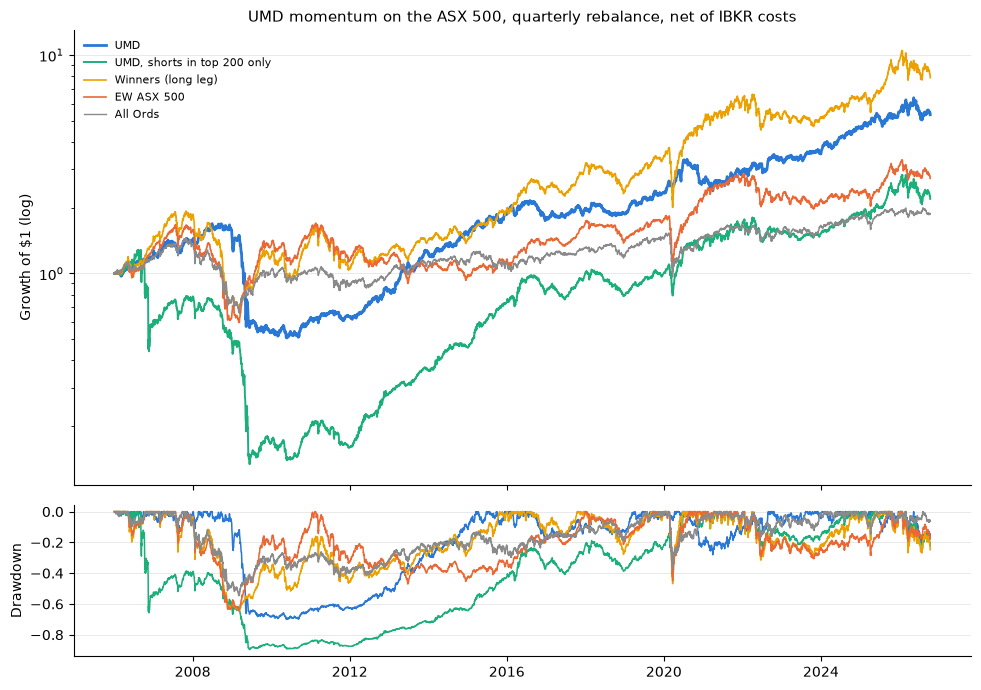

In [8]:
fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
for name, r, c, lw in [("UMD", umd, BLUE, 2.0), ("UMD, shorts in top 200 only", bts["UMD, shorts in top 200 only"]["net"], AQUA, 1.4),
                       ("Winners (long leg)", bts["Winners (long leg)"]["net"], YELLOW, 1.2),
                       ("EW ASX 500", ew, ORANGE, 1.2), ("All Ords", aord.fillna(0), GREY, 1.0)]:
    eq = (1 + r.loc["2006":]).cumprod()
    axs[0].plot(eq, color=c, lw=lw, label=name)
    axs[1].plot(eq / eq.cummax() - 1, color=c, lw=1.1)
axs[0].set_yscale("log")
axs[0].set_ylabel("Growth of $1 (log)")
axs[0].set_title("UMD momentum on the ASX 500, quarterly rebalance, net of IBKR costs", fontsize=11)
axs[0].legend(fontsize=8, frameon=False)
axs[1].set_ylabel("Drawdown")
for ax in axs:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", lw=0.6)
fig.tight_layout()
fig.savefig(RESULTS / "equity_curves.png", dpi=130)
plt.show()

* **UMD makes money in both halves.** After costs it earns 6.8% a year in 2006–16 and 12.1% in 2017–26, at about 16% volatility: a Sharpe of 0.39 and 0.85, and 0.58 over the whole period. Its beta to the market is close to zero, so almost all of that is alpha (9.0% a year, t = 2.4).
* **The first half is weak and includes a −70% drawdown** (2009, see section 7). Taken alone, 2006–16 is not statistically significant (t = 1.1).
* **Both sides contribute.** The winners beat the equal-weight ASX 500 by about 6% a year. The losers, held long, lose 4.9% a year while the market gains 6.1%, so shorting them adds as much again.
* **Restricting shorts to the 200 most liquid stocks does not work as a fix.** That book shorts far fewer names than it buys, so it is net long the market (beta 0.3–0.5), and it lost 90% in 2008–09. Section 6 tests a cleaner way to avoid single-stock shorts.

## 5. FIP screen: the quality of the momentum

**The idea ("frog in the pan").** A frog dropped in hot water jumps out; one in slowly heated water does not notice. Da, Gurun & Warachka (2014) argue investors behave the same way: they react to a big jump in a share price, but under-react to a long run of small gains. So momentum built from many small moves should continue for longer than momentum built from a few large ones.

**The measure.** Over the same 12-1 month window as the momentum score:

> FIP = sign(past return) × (% of days down − % of days up)

* A winner that rose on most days has a strongly **negative** FIP: smooth, high-quality momentum.
* A winner that got there in a handful of big days, and fell on most others, has a **positive** FIP: jumpy, low-quality momentum.
* For losers the sign flips, so a low score again means a smooth, steady decline.

**The screen** (Gray & Vogel's *Quantitative Momentum* recipe). At each rebalance, after the winners and losers are picked, keep only the **smoother half** of each group (lowest FIP). The book holds half as many names.

**What is compared.** UMD and the winners-only book, each with the screen ("smooth half"), without it, and with the opposite half ("jumpy half"). If the idea holds, smooth should beat no-screen, which should beat jumpy.

,winners held,losers held,winners: % of days up,winners: median FIP score,winners: median 12-1 return
no FIP screen,138.446,137.301,0.390,-0.024,0.820
FIP: smooth half,68.627,68.036,0.418,-0.063,0.824
FIP: jumpy half,69.819,69.265,0.363,0.010,0.834


ann_ret                 sharpe                 max_dd                alpha_ew                alpha_t_ew                cost_pa              
period                                2006-16 2017-26   FULL 2006-16 2017-26   FULL 2006-16 2017-26   FULL  2006-16 2017-26   FULL    2006-16 2017-26   FULL 2006-16 2017-26  FULL
strategy                                                                                                                                                                          
UMD | no FIP screen                     0.068   0.121  0.093   0.394   0.847  0.582  -0.701  -0.280 -0.701    0.071   0.100  0.088      1.202   2.173  2.272   0.046   0.048 0.047
UMD | FIP: smooth half                  0.111   0.203  0.155   0.469   1.175  0.738  -0.838  -0.352 -0.838    0.123   0.200  0.162      1.551   3.443  3.224   0.053   0.051 0.052
UMD | FIP: jumpy half                   0.002   0.021  0.011   0.010   0.120  0.057  -0.611  -0.340 -0.611   -0.004  -0.016 -0.007     -0.066  -0.310 -0.172   0.059   0.064 0.061
Winners | no FIP screen                 0.098   0.144  0.119   0.524   0.665  0.594  -0.644  -0.468 -0.644    0.052   0.042  0.048      2.061   1.624  2.653   0.016   0.019 0.018
Winners | FIP: smooth half              0.142   0.175  0.158   0.801   0.866  0.832  -0.615  -0.467 -0.615    0.101   0.085  0.095      3.481   2.734  4.444   0.018   0.020 0.019
Winners | FIP: jumpy half               0.046   0.103  0.073   0.209   0.414  0.311  -0.688  -0.544 -0.688   -0.005  -0.010 -0.006     -0.157  -0.286 -0.252   0.024   0.027 0.025
Losers (held long) | no FIP screen     -0.061  -0.035 -0.049  -0.330  -0.196 -0.268  -0.773  -0.580 -0.849   -0.107  -0.117 -0.112     -4.110  -4.855 -6.277   0.018   0.019 0.019
Losers (held long) | FIP: smooth half  -0.107  -0.088 -0.098  -0.490  -0.423 -0.459  -0.856  -0.741 -0.950   -0.156  -0.179 -0.167     -4.068  -5.271 -6.486   0.022   0.022 0.022
Losers (held long) | FIP: jumpy half   -0.023   0.009 -0.008  -0.118   0.054 -0.043  -0.742  -0.490 -0.742   -0.066  -0.065 -0.066     -2.021  -2.537 -3.126   0.025   0.026 0.025

difference, % a year      t
UMD                FIP: smooth half minus no FIP screen                   6.150  2.320
                   FIP: smooth half minus FIP: jumpy half                14.340  2.800
Winners            FIP: smooth half minus no FIP screen                   3.850  2.480
                   FIP: smooth half minus FIP: jumpy half                 8.500  2.760
Losers (held long) FIP: smooth half minus no FIP screen                  -4.920 -3.030
                   FIP: smooth half minus FIP: jumpy half                -9.010 -2.830

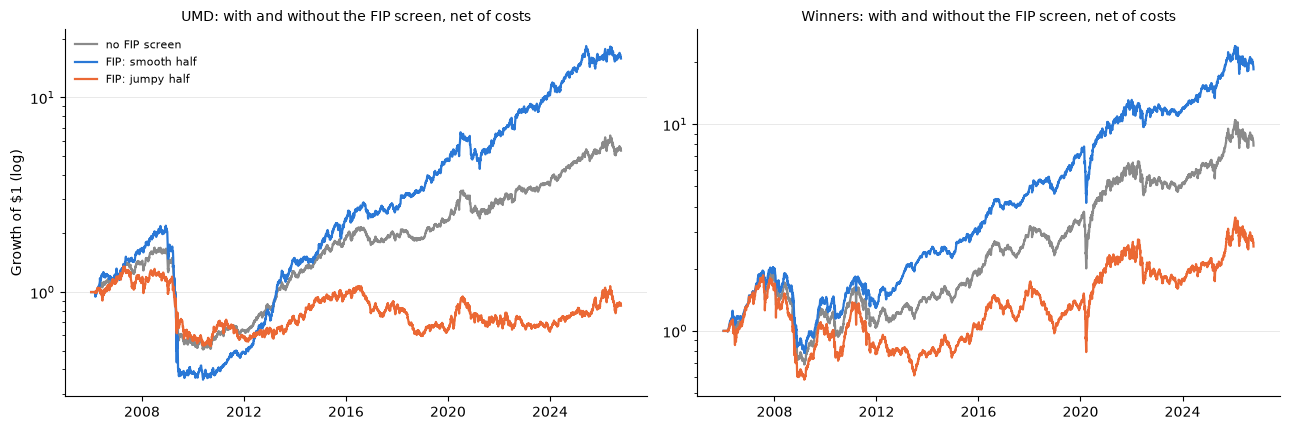

In [9]:
fip = fip_score(df)
fip_bts, fip_extra = {}, {}
for label, kind in [("no FIP screen", None), ("FIP: smooth half", "smooth"), ("FIP: jumpy half", "jumpy")]:
    w = umd_weights(df, fip=kind)
    for book, wb in [("UMD", w), ("Winners", w.clip(lower=0)), ("Losers (held long)", -w.clip(upper=0))]:
        fip_bts[(book, label)] = backtest_weights(wb, df)
    on = w.loc["2006":]
    fip_extra[label] = {"winners held": (on > 0).sum(axis=1).mean(), "losers held": (on < 0).sum(axis=1).mean(),
                        "winners: % of days up": np.mean([(df["ret"].loc[:d].iloc[-252:-21][on.columns[on.loc[d] > 0]] > 0).mean().mean() for d in on.index]),
                        "winners: median FIP score": np.mean([fip.loc[d][on.loc[d] > 0].median() for d in on.index]),
                        "winners: median 12-1 return": np.mean([mom_now.loc[d][on.loc[d] > 0].median() for d in on.index])}
display(pd.DataFrame(fip_extra).T.round(3))

fip_table = report({f"{book} | {label}": bt for (book, label), bt in fip_bts.items()}, aord)
fip_table["alpha_ew"] = report({f"{book} | {label}": bt for (book, label), bt in fip_bts.items()}, ew)["alpha"]
fip_table["alpha_t_ew"] = report({f"{book} | {label}": bt for (book, label), bt in fip_bts.items()}, ew)["alpha_t"]
fip_table.to_csv(RESULTS / "03_fip.csv")
order = [f"{book} | {label}" for book in ("UMD", "Winners", "Losers (held long)") for label in ("no FIP screen", "FIP: smooth half", "FIP: jumpy half")]
display(fip_table[["ann_ret", "ann_vol", "sharpe", "max_dd", "alpha_ew", "alpha_t_ew", "turnover_pa", "cost_pa"]].unstack("period").reindex(order)
        .drop(columns=["ann_vol", "turnover_pa"], level=0).round(3))

# is the difference between smooth and jumpy reliable?  paired difference of daily returns
diff_rows = {}
for book in ("UMD", "Winners", "Losers (held long)"):
    for a, b in [("FIP: smooth half", "no FIP screen"), ("FIP: smooth half", "FIP: jumpy half")]:
        d = (fip_bts[(book, a)]["net"] - fip_bts[(book, b)]["net"]).loc["2006":]
        fit = sm.OLS(d.values, np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
        diff_rows[(book, f"{a} minus {b}")] = {"difference, % a year": 100 * d.mean() * TRADING_DAYS, "t": fit.tvalues[0]}
fip_diff = pd.DataFrame(diff_rows).T
fip_diff.to_csv(RESULTS / "03b_fip_differences.csv")
display(fip_diff.round(2))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.4), sharey=False)
for ax, book in zip(axs, ("UMD", "Winners")):
    for label, c in [("no FIP screen", GREY), ("FIP: smooth half", BLUE), ("FIP: jumpy half", ORANGE)]:
        ax.plot((1 + fip_bts[(book, label)]["net"].loc["2006":]).cumprod(), color=c, lw=1.6, label=label)
    ax.set_yscale("log")
    ax.set_title(f"{book}: with and without the FIP screen, net of costs", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", lw=0.6)
axs[0].set_ylabel("Growth of $1 (log)")
axs[0].legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(RESULTS / "fip.png", dpi=130)
plt.show()

**The FIP screen helps, on both sides.**

| Full period, after costs | No screen | Smooth half | Jumpy half |
|---|---|---|---|
| UMD: return a year | 9.3% | **15.5%** | 1.1% |
| UMD: Sharpe | 0.58 | **0.74** | 0.06 |
| Winners: return a year | 11.9% | **15.8%** | 7.3% |
| Winners: Sharpe | 0.59 | **0.83** | 0.31 |
| Winners: alpha vs EW ASX 500 (t) | 4.8% (2.7) | **9.5% (4.4)** | −0.6% (−0.3) |
| Losers held long: return a year | −4.9% | **−9.8%** | −0.8% |

* **The ordering is exactly what the idea predicts:** smooth beats no screen, which beats jumpy, for winners (higher return) and for losers (lower return, which is what a short wants).
* **Smooth winners carry all of the winners' edge.** The jumpy half has no alpha against the market at all. Winners that got there in a few big days do not keep going.
* **The differences are statistically reliable.** Smooth minus no-screen is +3.9% a year for winners (t = 2.5) and +6.2% for UMD (t = 2.3); smooth minus jumpy is +8.5% (t = 2.8) and +14.3% (t = 2.8).
* **It holds in both halves** for the winners (Sharpe 0.80 and 0.87, against 0.52 and 0.67 without the screen).
* **What it costs:** the book holds about 69 names a side instead of 138, turnover rises from 7.3× to 8.9× capital a year, and UMD's volatility rises from 16% to 21%. The screened UMD also fell further in 2009 (−84% against −70%): smooth losers were the hardest-hit stocks and rebounded most.
* The screen was applied as published (keep the smoother half); nothing was tuned.

## 6. Long-only winners, hedged with index futures

Shorting individual losers is the hard part of UMD on the ASX: many are small and cannot be borrowed. The alternative keeps only the **winners** and removes the market exposure by shorting the index against them, in practice with SPI 200 futures.

* **Long side:** the winners portfolio, 100% of capital, rebalanced quarterly, with all trading costs.
* **Hedge:** each day, short the index in proportion to the book's beta over the previous 126 days (information up to yesterday only). Its return is −β × the index return, with 2 bps charged on changes in the hedge.
* A **fixed** hedge (always short 100% of capital in the index) is shown for comparison: it needs no beta estimate.
* The All Ords stands in for the futures. It is a price index, so the hedge here pays no dividends and earns no interest; real futures embed both, and the two roughly offset. That is a simplification.

Run with and without the FIP screen.

ann_ret  ann_vol  sharpe  max_dd  alpha  alpha_t   beta
strategy                                   period                                                          
Winners, unhedged                          2006-16    0.098    0.187   0.524  -0.644  0.073    1.547  0.768
                                           2017-26    0.144    0.216   0.665  -0.468  0.086    1.743  1.053
                                           FULL       0.119    0.201   0.594  -0.644  0.082    2.373  0.877
Winners, index-hedged (rolling beta)       2006-16    0.087    0.129   0.679  -0.427  0.088    1.847 -0.018
                                           2017-26    0.088    0.147   0.599  -0.263  0.088    1.760  0.008
                                           FULL       0.088    0.138   0.637  -0.427  0.088    2.555 -0.008
Winners, index-hedged (fixed 1.0)          2006-16    0.065    0.136   0.477  -0.329  0.073    1.547 -0.232
                                           2017-26    0.089    0.152   0.585  -0.252  0.086    1.743  0.053
                                           FULL       0.076    0.144   0.530  -0.329  0.082    2.373 -0.123
Winners + FIP, unhedged                    2006-16    0.142    0.178   0.801  -0.615  0.119    2.692  0.715
                                           2017-26    0.175    0.203   0.866  -0.467  0.122    2.728  0.980
                                           FULL       0.158    0.190   0.832  -0.615  0.123    3.872  0.816
Winners + FIP, index-hedged (rolling beta) 2006-16    0.137    0.126   1.090  -0.406  0.138    3.059 -0.010
                                           2017-26    0.127    0.139   0.915  -0.245  0.127    2.865  0.003
                                           FULL       0.132    0.132   1.002  -0.406  0.133    4.187 -0.005
UMD (single-stock shorts)                  2006-16    0.068    0.174   0.394  -0.701  0.068    1.133 -0.000
                                           2017-26    0.121    0.142   0.847  -0.280  0.112    2.471  0.153
                                           FULL       0.093    0.160   0.582  -0.701  0.090    2.352  0.058
UMD + FIP (single-stock shorts)            2006-16    0.111    0.237   0.469  -0.838  0.115    1.379 -0.123
                                           2017-26    0.203    0.173   1.175  -0.352  0.200    3.453  0.056
                                           FULL       0.155    0.209   0.738  -0.838  0.157    3.026 -0.054

correlation of daily returns, hedged winners vs UMD: 0.48


,"Winners, unhedged","Winners, index-hedged (rolling beta)","Winners + FIP, index-hedged (rolling beta)",UMD (single-stock shorts)
date,,,,
2006,43.4%,31.6%,32.4%,22.6%
2007,28.2%,13.3%,26.7%,16.1%
2008,-58.8%,-37.9%,-32.8%,4.5%
2009,58.2%,35.7%,33.8%,-63.9%
2010,23.3%,23.3%,21.2%,15.6%
2011,-29.1%,-13.4%,-8.2%,2.6%
2012,19.6%,7.0%,25.8%,32.7%
2013,14.0%,5.3%,24.6%,48.0%
2014,-0.6%,-1.2%,-4.5%,20.9%


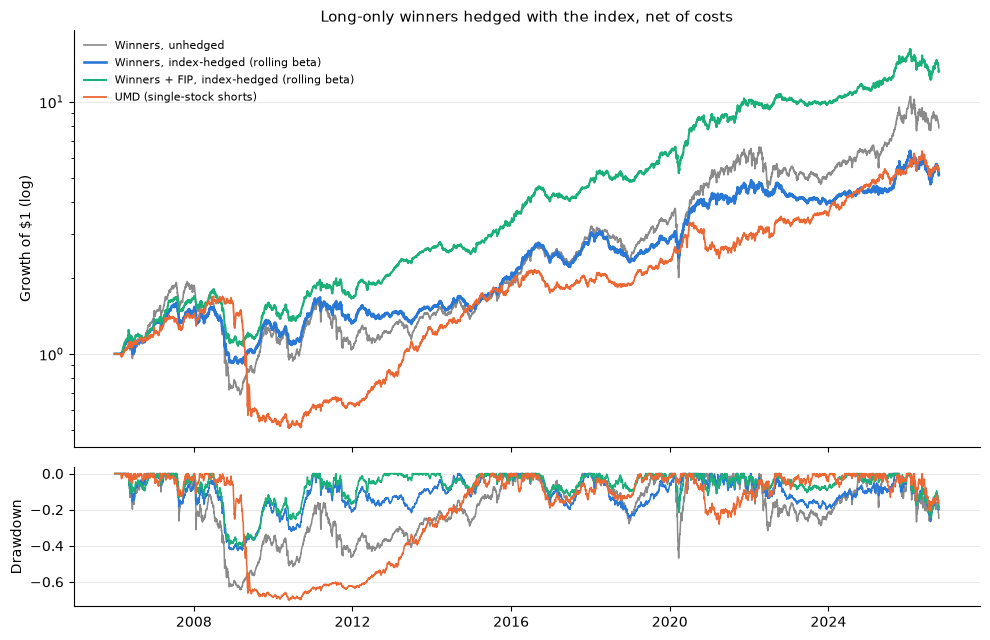

In [10]:
mkt = aord.fillna(0.0)


def index_hedge(r, window=126, fixed=None):
    if fixed is not None:
        return r - fixed * mkt
    cov = (r * mkt).rolling(window, min_periods=60).mean() - r.rolling(window, min_periods=60).mean() * mkt.rolling(window, min_periods=60).mean()
    beta = (cov / mkt.rolling(window, min_periods=60).var()).shift(1).fillna(0.9)
    return r - beta * mkt - beta.diff().abs().fillna(0) * 2e-4


win, win_fip = fip_bts[("Winners", "no FIP screen")]["net"], fip_bts[("Winners", "FIP: smooth half")]["net"]
hedge_books = {"Winners, unhedged": win,
               "Winners, index-hedged (rolling beta)": index_hedge(win),
               "Winners, index-hedged (fixed 1.0)": index_hedge(win, fixed=1.0),
               "Winners + FIP, unhedged": win_fip,
               "Winners + FIP, index-hedged (rolling beta)": index_hedge(win_fip),
               "UMD (single-stock shorts)": umd,
               "UMD + FIP (single-stock shorts)": fip_bts[("UMD", "FIP: smooth half")]["net"]}
hedge_table = pd.DataFrame({(name, per): stats(r.loc[sl], aord) for name, r in hedge_books.items() for per, sl in PERIODS}).T.rename_axis(["strategy", "period"])
hedge_table.to_csv(RESULTS / "04_hedged_long_only.csv")
display(hedge_table[["ann_ret", "ann_vol", "sharpe", "max_dd", "alpha", "alpha_t", "beta"]])

hy = pd.DataFrame(hedge_books).loc["2006":]
hedge_yearly = hy.groupby(hy.index.year).apply(lambda x: (1 + x).prod() - 1)[["Winners, unhedged", "Winners, index-hedged (rolling beta)",
                                                                             "Winners + FIP, index-hedged (rolling beta)", "UMD (single-stock shorts)"]]
hedge_yearly.to_csv(RESULTS / "04b_hedged_yearly.csv")
print("correlation of daily returns, hedged winners vs UMD:", round(hy["Winners, index-hedged (rolling beta)"].corr(hy["UMD (single-stock shorts)"]), 2))
display(hedge_yearly.style.format("{:.1%}").background_gradient(cmap="RdBu", vmin=-0.4, vmax=0.4))

fig, axs = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
for name, c, lw in [("Winners, unhedged", GREY, 1.2), ("Winners, index-hedged (rolling beta)", BLUE, 1.9),
                    ("Winners + FIP, index-hedged (rolling beta)", AQUA, 1.5), ("UMD (single-stock shorts)", ORANGE, 1.3)]:
    eq = (1 + hedge_books[name].loc["2006":]).cumprod()
    axs[0].plot(eq, color=c, lw=lw, label=name)
    axs[1].plot(eq / eq.cummax() - 1, color=c, lw=1.1)
axs[0].set_yscale("log")
axs[0].set_ylabel("Growth of $1 (log)")
axs[0].set_title("Long-only winners hedged with the index, net of costs", fontsize=11)
axs[0].legend(fontsize=8, frameon=False)
axs[1].set_ylabel("Drawdown")
for ax in axs:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5", lw=0.6)
fig.tight_layout()
fig.savefig(RESULTS / "hedged_long_only.png", dpi=130)
plt.show()

**The hedged long-only book works, and with the FIP screen it is the best result here.**

| Full period, after costs | Return a year | Volatility | Sharpe | Max drawdown | Beta |
|---|---|---|---|---|---|
| Winners, unhedged | 11.9% | 20.1% | 0.59 | −64% | 0.88 |
| Winners, index-hedged | 8.8% | 13.8% | 0.64 | −43% | −0.01 |
| **Winners + FIP, index-hedged** | **13.2%** | **13.2%** | **1.00** | **−41%** | **−0.01** |
| UMD (single-stock shorts) | 9.3% | 16.0% | 0.58 | −70% | 0.06 |
| UMD + FIP | 15.5% | 20.9% | 0.74 | −84% | −0.05 |

* **Hedging removes the market and keeps the alpha.** Beta drops from 0.88 to zero and volatility from 20% to 14%, while the alpha is unchanged at about 8.8% a year (t = 2.6).
* **It matches UMD's return with a smaller drawdown and no stock borrowing.** Hedged winners earn 8.8% a year against 9.3% for UMD, with a −43% drawdown against −70%.
* **It avoids the momentum crash.** In 2009 UMD lost 64% because its short losers rebounded 152%. The hedged winners made **+36%** that year: the index hedge rose 33%, far less than the losers did.
* **Its bad year is different: 2008 (−38%).** Small and mid-cap winners fell much further than the large-cap index used to hedge them. The hedge removes *market* risk, not the risk that smaller stocks fall harder.
* **With the FIP screen the hedged book has a Sharpe of 1.0 and is consistent across the two halves** (1.09 and 0.92; alpha 13.3% a year, t = 4.2).
* **Rolling beta or a fixed hedge?** The rolling-beta hedge is a little better (Sharpe 0.64 against 0.53) because the winners' beta moves between about 0.75 and 1.05.
* The two market-neutral books are only moderately correlated (0.48), so they are not the same bet.

## 7. Legs, years and momentum crashes

Momentum is known for rare, sharp losses when a falling market turns: the losers it is short rebound hardest (Daniel & Moskowitz 2016). The first table gives calendar-year returns of UMD and its two sides. The second lists UMD's worst quarters next to what the market did.

In [11]:
legs = pd.DataFrame({"UMD": umd, "winners": bts["Winners (long leg)"]["net"], "losers (long)": bts["Losers (held long)"]["net"],
                     "EW ASX 500": ew, "All Ords": aord}).loc["2006":].fillna(0)
yearly = legs.groupby(legs.index.year).apply(lambda x: (1 + x).prod() - 1)
yearly.to_csv(RESULTS / "05_yearly.csv")
full = yearly.loc[:2025]
print(f"UMD positive in {(full['UMD'] > 0).sum()} of {len(full)} full years;  winners beat losers in {(full['winners'] > full['losers (long)']).sum()}")
display(yearly.style.format("{:.1%}").background_gradient(cmap="RdBu", vmin=-0.4, vmax=0.4))

quarterly = legs.groupby(legs.index.to_period("Q")).apply(lambda x: (1 + x).prod() - 1)
worst = quarterly.nsmallest(8, "UMD")
worst.to_csv(RESULTS / "05b_worst_quarters.csv")
print(f"UMD quarters: {(quarterly['UMD'] > 0).mean():.0%} positive;  correlation of quarterly UMD with the All Ords: {quarterly['UMD'].corr(quarterly['All Ords']):.2f}")
worst.style.format("{:.1%}")

UMD positive in 17 of 20 full years;  winners beat losers in 19


,UMD,winners,losers (long),EW ASX 500,All Ords
date,,,,,
2006,22.6%,43.4%,13.1%,31.0%,19.9%
2007,16.1%,28.2%,7.8%,20.5%,13.8%
2008,4.5%,-58.8%,-62.7%,-58.6%,-43.0%
2009,-63.9%,58.2%,152.2%,106.0%,33.4%
2010,15.6%,23.3%,4.6%,15.6%,-0.7%
2011,2.6%,-29.1%,-34.2%,-26.8%,-15.2%
2012,32.7%,19.6%,-18.1%,0.1%,13.5%
2013,48.0%,14.0%,-32.1%,-6.6%,14.8%
2014,20.9%,-0.6%,-25.2%,-9.0%,0.7%


UMD quarters: 70% positive;  correlation of quarterly UMD with the All Ords: -0.02


,UMD,winners,losers (long),EW ASX 500,All Ords
date,,,,,
2009Q2,-51.0%,12.5%,44.4%,29.5%,11.8%
2009Q1,-17.7%,1.9%,18.0%,9.3%,-3.5%
2020Q4,-12.6%,10.0%,20.2%,16.7%,14.0%
2016Q4,-12.6%,-8.7%,2.6%,-2.6%,3.5%
2021Q1,-9.7%,4.9%,14.2%,9.7%,2.4%
2008Q4,-9.5%,-36.1%,-28.8%,-31.7%,-21.0%
2020Q3,-7.7%,12.1%,21.4%,16.7%,0.1%
2009Q3,-6.2%,38.3%,43.3%,40.8%,20.0%


* UMD was positive in **17 of 20 full years**, and its quarterly returns are uncorrelated with the market (−0.02).
* **2009 is the momentum crash: −64%**, with −51% in the second quarter alone. Coming out of the 2008 collapse, the losers it was short rebounded 152% while the winners rose 58%.
* The other bad quarters have the same shape on a smaller scale (late 2016, late 2020, early 2021): a sharp recovery in beaten-down stocks. That is the risk this strategy carries, and a quarterly rebalance is slow to react to it.
* In the market's down years the short side paid: UMD made +4.5% in 2008 and +15% in 2022.

## 8. Costs, borrow and account size

* **Cost models:** no costs; IBKR commission only; commission plus half-spread (the headline); twice the spread; and the headline with no borrow fee and with a 3% borrow fee.
* **IBKR's A$6 minimum per order:** applied for three account sizes. A quarterly rebalance sends a few hundred orders four times a year, so the minimum matters far less than for a daily strategy.

In [12]:
COST_MODELS = {"no costs": dict(commission_bps=0, spread=0, borrow=0),
               "IBKR commission only (0.08%), no borrow": dict(spread=0, borrow=0),
               "IBKR commission + half-spread, 1% borrow (headline)": dict(),
               "IBKR commission + 2 x half-spread, 1% borrow": dict(spread=2.0),
               "headline, no borrow fee": dict(borrow=0),
               "headline, 3% borrow fee": dict(borrow=0.03)}
cost_bts = {name: backtest_weights(W, df, **kw) for name, kw in COST_MODELS.items()}
costs = report(cost_bts, aord)
costs.to_csv(RESULTS / "06_costs.csv")
display(costs[["cost_pa", "ann_ret", "sharpe", "alpha", "alpha_t"]].unstack("period").reindex(list(cost_bts)).round(3))

min_bts = {f"A${c / 1e6:g}m account": backtest_weights(W, df, capital=c) for c in [0.1e6, 1e6, 10e6]}
min_fee = report(min_bts, aord)
min_fee.to_csv(RESULTS / "06b_minimum_fee.csv")
b = bts["UMD"].loc["2006":]
H = hold["UMD"].loc["2006":]
print(f"orders per rebalance: {b.loc[b['orders'] > 0, 'orders'].mean():.0f};  one-way turnover per rebalance: {b.loc[b['turnover'] > 0, 'turnover'].mean():.0%} of capital "
      f"(gross exposure is 200%);  median half-spread, longs {1e4 * HALF_SPREAD.where(H > 0).median(axis=1).median():.0f} bps, shorts {1e4 * HALF_SPREAD.where(H < 0).median(axis=1).median():.0f} bps")
min_fee[["cost_pa", "ann_ret", "sharpe"]].unstack("period").reindex(list(min_bts)).round(3)

cost_pa               ann_ret                sharpe                 alpha               alpha_t              
period                                             2006-16 2017-26  FULL 2006-16 2017-26  FULL 2006-16 2017-26  FULL 2006-16 2017-26  FULL 2006-16 2017-26  FULL
strategy                                                                                                                                                        
no costs                                             0.000   0.000 0.000   0.115   0.169 0.140   0.668   1.197 0.887   0.115   0.161 0.138   1.912   3.558 3.603
IBKR commission only (0.08%), no borrow              0.006   0.006 0.006   0.109   0.163 0.135   0.632   1.157 0.850   0.109   0.155 0.132   1.810   3.435 3.449
IBKR commission + half-spread, 1% borrow (headl...   0.046   0.048 0.047   0.068   0.121 0.093   0.394   0.847 0.582   0.068   0.112 0.090   1.133   2.471 2.352
IBKR commission + 2 x half-spread, 1% borrow         0.077   0.081 0.079   0.038   0.088 0.061   0.214   0.602 0.377   0.038   0.079 0.059   0.622   1.716 1.511
headline, no borrow fee                              0.037   0.039 0.038   0.078   0.130 0.103   0.450   0.916 0.644   0.078   0.122 0.100   1.298   2.689 2.610
headline, 3% borrow fee                              0.066   0.068 0.067   0.049   0.101 0.073   0.280   0.709 0.459   0.049   0.093 0.071   0.805   2.037 1.837

orders per rebalance: 366;  one-way turnover per rebalance: 184% of capital (gross exposure is 200%);  median half-spread, longs 19 bps, shorts 21 bps


cost_pa               ann_ret                sharpe              
period         2006-16 2017-26  FULL 2006-16 2017-26  FULL 2006-16 2017-26  FULL
strategy                                                                        
A$0.1m account   0.121   0.138 0.129  -0.006   0.031 0.011  -0.031   0.199 0.068
A$1m account     0.049   0.053 0.051   0.065   0.116 0.089   0.376   0.815 0.559
A$10m account    0.046   0.049 0.047   0.068   0.121 0.093   0.393   0.846 0.582

* **Costs take about 4.7% a year**, a third of the 14.0% earned before costs. Each rebalance trades 184% of capital (out of 200% gross exposure), four times a year.
* **The spread is most of it.** Commission is 0.6% a year. The stocks held have a median half-spread of about 20 bps, which adds about 3%. The assumed 1% borrow fee adds 1%.
* **Sensitivity:** with twice the spread the return falls to 6.1% a year (Sharpe 0.38). With a 3% borrow fee it is 7.3% (Sharpe 0.46).
* **Account size is not a problem above about A$1m.** About 370 orders go out per rebalance, so IBKR's A$6 minimum costs about A$8,800 a year: negligible on A$1m or more (Sharpe 0.56 against 0.58), most of the return on A$100,000.
* The winners-only books trade half as much (3.4–4.2× capital a year) and cost about 1.8–1.9% a year, with no borrow fee.

## 9. Robustness: rebalance frequency and construction

These are checks, not a search. The quarterly, 12-1, 30%/30%, size-neutral rule stays the strategy. All rows are plain UMD with no FIP screen.

* **Rebalance timing:** the month before each quarter-ending month (the strategy) against calendar quarter-ends.
* **Rebalance frequency:** monthly (the textbook), half-yearly, yearly.
* **Formation window:** 6-1 and 9-1 months instead of 12-1, and 12-0 (no skipped month).
* **Breakpoints:** top and bottom 10% and 20% instead of 30%.
* **No size split:** winners and losers picked across all members at once.

In [13]:
variants = {"quarterly (Feb/May/Aug/Nov), 12-1, 30/30, size-neutral (the strategy)": dict(),
            "quarterly at calendar quarter-ends (Mar/Jun/Sep/Dec)": dict(freq="QE"),
            "monthly rebalance": dict(freq="M"),
            "half-yearly rebalance (May/Nov)": dict(freq="H"),
            "yearly rebalance (Nov)": dict(freq="Y"),
            "6-1 formation": dict(lookback=126),
            "9-1 formation": dict(lookback=189),
            "12-0 formation (no skipped month)": dict(skip=0),
            "top/bottom 20%": dict(top=0.20),
            "top/bottom 10%": dict(top=0.10),
            "no size split": dict(size_neutral=False)}
var_bts = {name: backtest_weights(umd_weights(df, **kw), df) for name, kw in variants.items()}
var_table = report(var_bts, aord)
gross = pd.DataFrame({(name, per): stats(bt["gross"].loc[sl])["sharpe"] for name, bt in var_bts.items() for per, sl in PERIODS}, index=["gross_sharpe"]).T
var_table = var_table.join(gross.rename_axis(var_table.index.names))
var_table.to_csv(RESULTS / "07_variants.csv")
var_table[["ann_ret", "sharpe", "gross_sharpe", "max_dd", "turnover_pa", "cost_pa"]].unstack("period").reindex(list(variants)).round(2)

ann_ret                 sharpe                gross_sharpe                 max_dd                turnover_pa                cost_pa              
period                                             2006-16 2017-26   FULL 2006-16 2017-26   FULL      2006-16 2017-26   FULL 2006-16 2017-26   FULL     2006-16 2017-26   FULL 2006-16 2017-26  FULL
strategy                                                                                                                                                                                            
quarterly (Feb/May/Aug/Nov), 12-1, 30/30, size-...   0.070   0.120  0.090   0.390   0.850  0.580        0.670   1.200  0.890  -0.700  -0.280 -0.700       7.560   7.020  7.300   0.050   0.050 0.050
quarterly at calendar quarter-ends (Mar/Jun/Sep...   0.070   0.120  0.090   0.480   0.790  0.620        0.780   1.140  0.940  -0.550  -0.220 -0.550       7.210   7.210  7.210   0.040   0.050 0.050
monthly rebalance                                    0.080   0.100  0.090   0.550   0.670  0.600        1.070   1.230  1.150  -0.550  -0.210 -0.550      13.030  12.640 12.850   0.080   0.080 0.080
half-yearly rebalance (May/Nov)                      0.050   0.100  0.070   0.290   0.720  0.480        0.510   0.970  0.710  -0.740  -0.270 -0.740       5.110   4.610  4.870   0.030   0.030 0.030
yearly rebalance (Nov)                               0.020   0.110  0.070   0.040   0.870  0.180        0.110   1.050  0.250  -0.960  -0.230 -0.960       4.420   2.820  3.660   0.030   0.020 0.030
6-1 formation                                        0.040   0.060  0.050   0.230   0.470  0.330        0.570   0.930  0.710  -0.700  -0.260 -0.700       9.850   9.620  9.740   0.060   0.060 0.060
9-1 formation                                        0.070   0.100  0.080   0.340   0.700  0.480        0.600   1.080  0.780  -0.740  -0.250 -0.740       8.390   7.980  8.200   0.050   0.050 0.050
12-0 formation (no skipped month)                    0.090   0.150  0.120   0.490   1.070  0.730        0.750   1.410  1.020  -0.730  -0.200 -0.730       7.350   6.770  7.080   0.050   0.050 0.050
top/bottom 20%                                       0.090   0.160  0.120   0.370   0.900  0.560        0.580   1.220  0.810  -0.800  -0.280 -0.800       8.610   7.780  8.220   0.050   0.050 0.050
top/bottom 10%                                      -0.870   0.160 -0.380  -0.270   0.680 -0.160       -0.250   0.950 -0.140  -1.010  -0.380 -1.010      10.270   8.670  9.520   0.060   0.060 0.060
no size split                                        0.070   0.130  0.100   0.410   0.900  0.610        0.690   1.250  0.920  -0.750  -0.230 -0.750       7.690   7.120  7.420   0.050   0.050 0.050

* **Rebalancing before the quarter-ending month made no difference to performance.** Feb/May/Aug/Nov gives a Sharpe of 0.58 and calendar quarter-ends 0.62. The gap comes from 2009: the May 2009 rebalance kept the book short the losers through the worst of the rebound. There is no sign here of a window-dressing benefit, though one crash dominates the comparison.
* **Monthly rebalancing earns more before costs and the same after.** Its gross Sharpe is 1.15 against 0.89, but it trades almost twice as much and costs 8% a year. After costs it is level with quarterly (0.60).
* **Slower than quarterly is worse** (half-yearly 0.48, yearly 0.18).
* **12 months is the right window.** 6-1 and 9-1 are weaker.
* **A narrow book is dangerous.** With only the top and bottom 10%, the long-short book lost more than its entire capital in the 2009 rebound. Concentrating UMD into fewer, more extreme names raises the crash risk sharply.

## 10. Size and liquidity of what is held

* **Does the size split work?** UMD is regressed on the market and a size factor (equal-weight small half minus equal-weight big half, by traded value).
* **Liquidity:** the median traded value of the longs and of the shorts, by year. The shorts matter most: thin stocks are hard to borrow.

In [14]:
mem = df["member"].loc[rebalance_dates("Q")]
adv_rank = df["adv"].where(df["member"]).rank(axis=1, pct=True).loc[mem.index]
small_w, big_w = ((adv_rank <= 0.5) & mem).astype(float), ((adv_rank > 0.5) & mem).astype(float)
smb = (backtest_weights(small_w.div(small_w.sum(axis=1), axis=0).dropna(how="all"), df, commission_bps=0, spread=0, borrow=0)["net"]
       - backtest_weights(big_w.div(big_w.sum(axis=1), axis=0).dropna(how="all"), df, commission_bps=0, spread=0, borrow=0)["net"])
factors = pd.DataFrame({"market": aord.fillna(0), "size (small - big)": smb})
rows = {}
for name in ["UMD", "UMD, shorts in top 200 only"]:
    for per, sl in PERIODS:
        fit = sm.OLS(bts[name]["net"].loc[sl], sm.add_constant(factors.loc[sl])).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
        rows[(name, per)] = {"alpha": fit.params["const"] * TRADING_DAYS, "alpha_t": fit.tvalues["const"],
                             "beta_market": fit.params["market"], "beta_size": fit.params["size (small - big)"]}
size_ctrl = pd.DataFrame(rows).T
size_ctrl.to_csv(RESULTS / "08_size_control.csv")
display(size_ctrl)

adv_m = df["adv"] / 1e6
liq = pd.DataFrame({"longs: median traded value, A$m/day": adv_m.where(hold["UMD"] > 0).median(axis=1),
                    "shorts: median traded value, A$m/day": adv_m.where(hold["UMD"] < 0).median(axis=1),
                    "shorts in the top 200, share": ((hold["UMD"] < 0) & top200).sum(axis=1) / (hold["UMD"] < 0).sum(axis=1)}).loc["2006":]
liq = liq.groupby(liq.index.year).median()
liq.to_csv(RESULTS / "09_liquidity.csv")
liq.T.round(2)

alpha  alpha_t  beta_market  beta_size
UMD                         2006-16  0.064    1.079       -0.073     -0.213
                            2017-26  0.119    2.617        0.241      0.280
                            FULL     0.090    2.339        0.059      0.000
UMD, shorts in top 200 only 2006-16  0.020    0.219        0.285      0.289
                            2017-26  0.109    2.843        0.754      0.879
                            FULL     0.063    1.187        0.479      0.546

date,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
"longs: median traded value, A$m/day",0.060,0.090,0.050,0.080,0.060,0.060,0.090,0.090,0.090,0.090,...,0.110,0.170,0.240,0.440,0.760,0.770,0.750,0.860,1.330,2.020
"shorts: median traded value, A$m/day",0.050,0.090,0.050,0.080,0.060,0.060,0.070,0.090,0.090,0.090,...,0.100,0.160,0.180,0.460,0.790,0.710,0.640,0.710,1.200,1.970
"shorts in the top 200, share",0.500,0.460,0.450,0.540,0.450,0.410,0.420,0.460,0.460,0.450,...,0.390,0.390,0.360,0.390,0.410,0.370,0.320,0.350,0.380,0.410


* **The size split works for the main book:** its size beta is zero over the full period, and the alpha is unchanged after the size control (9.0% a year, t = 2.3).
* **The stocks are thin.** Because winners and losers are taken equally from the big and small halves, the median holding sits around the 250th most liquid stock: under A$0.1m a day until 2017 and about A$1–2m now. Fewer than half of the shorts are in the top 200.
* **This is the main obstacle to trading the short side**, and the reason the index-hedged winners in section 6 matter. The longs are just as thin, so capacity is small either way.

## 11. Is the return statistically significant?

UMD's benchmark is zero, so the question is simply whether its average return is reliably above zero.

* **t-statistic of the mean daily return** with Newey-West standard errors.
* **Stationary block bootstrap** (Politis & Romano; blocks of 20 days on average, 2,000 resamples): a 95% interval for the annual return and the Sharpe ratio, and the share of resamples with a return at or below zero.
* **Signal-shuffle test:** on every rebalance date the momentum scores are shuffled among the stocks within each size half, so the book has the same structure (same number of longs and shorts, same dates, same costs) but random picks. It is run on plain UMD. 200 shuffles give a p-value floor of 0.005. This asks whether *momentum* is what makes the money, or whether any long-short book of these stocks would have.

ann_ret  t (Newey-West)  ret 2.5%  ret 97.5%  sharpe  sharpe 2.5%  sharpe 97.5%  p(return <= 0)
UMD                         2006-16    0.068           1.126    -0.090      0.188   0.394       -0.429         1.327           0.165
                            2017-26    0.121           2.656     0.031      0.206   0.847        0.220         1.488           0.004
                            FULL       0.093           2.408     0.001      0.168   0.582        0.005         1.159           0.024
UMD + FIP                   2006-16    0.111           1.309    -0.103      0.290   0.469       -0.354         1.602           0.130
                            2017-26    0.203           3.533     0.095      0.308   1.175        0.533         1.799           0.000
                            FULL       0.155           2.944     0.029      0.262   0.738        0.125         1.460           0.008
Winners, index-hedged       2006-16    0.087           1.861    -0.021      0.192   0.679       -0.161         1.577           0.061
                            2017-26    0.088           1.779    -0.008      0.185   0.599       -0.055         1.277           0.036
                            FULL       0.088           2.573     0.014      0.158   0.637        0.100         1.174           0.010
Winners + FIP, index-hedged 2006-16    0.137           3.085     0.040      0.235   1.091        0.312         1.904           0.003
                            2017-26    0.127           2.884     0.036      0.215   0.915        0.251         1.559           0.003
                            FULL       0.132           4.218     0.057      0.202   1.002        0.428         1.540           0.000
Winners minus EW ASX 500    2006-16    0.056           2.265     0.000      0.110   0.725        0.004         1.460           0.024
                            2017-26    0.062           2.299     0.016      0.112   0.725        0.180         1.344           0.008
                            FULL       0.059           3.225     0.022      0.093   0.724        0.267         1.176           0.002

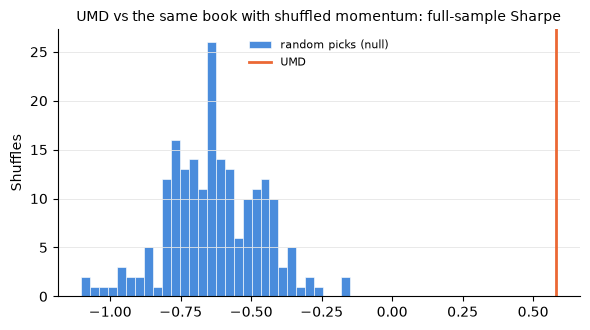

,observed Sharpe,null p5,null median,null p95,p-value
UMD,0.582,-0.900,-0.643,-0.357,0.005


In [15]:
def stationary_bootstrap_idx(T, B, mean_block, rng):
    idx = np.empty((B, T), dtype=np.int64)
    idx[:, 0] = rng.integers(0, T, B)
    jump = rng.random((B, T)) < 1 / mean_block
    fresh = rng.integers(0, T, (B, T))
    for t in range(1, T):
        idx[:, t] = np.where(jump[:, t], fresh[:, t], (idx[:, t - 1] + 1) % T)
    return idx


def nw_t(r):
    fit = sm.OLS(r.values, np.ones(len(r))).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
    return fit.tvalues[0]


brng = np.random.default_rng(11)
rows = {}
sig_series = {"UMD": umd, "UMD + FIP": hedge_books["UMD + FIP (single-stock shorts)"],
              "Winners, index-hedged": hedge_books["Winners, index-hedged (rolling beta)"],
              "Winners + FIP, index-hedged": hedge_books["Winners + FIP, index-hedged (rolling beta)"],
              "Winners minus EW ASX 500": bts["Winners (long leg)"]["net"] - ew}
for label, series in sig_series.items():
    for per, sl in PERIODS:
        x = series.loc[sl].values
        idx = stationary_bootstrap_idx(len(x), 2000, 20, brng)
        xb = x[idx]
        ann, sr = xb.mean(axis=1) * TRADING_DAYS, xb.mean(axis=1) / xb.std(axis=1) * np.sqrt(TRADING_DAYS)
        rows[(label, per)] = {"ann_ret": x.mean() * TRADING_DAYS, "t (Newey-West)": nw_t(pd.Series(x)),
                              "ret 2.5%": np.percentile(ann, 2.5), "ret 97.5%": np.percentile(ann, 97.5),
                              "sharpe": x.mean() / x.std() * np.sqrt(TRADING_DAYS), "sharpe 2.5%": np.percentile(sr, 2.5),
                              "sharpe 97.5%": np.percentile(sr, 97.5), "p(return <= 0)": max((ann <= 0).mean(), 1 / 2000)}
signif = pd.DataFrame(rows).T
signif.to_csv(RESULTS / "10_significance.csv")
display(signif.round(3))

N_PERM = 200
prng = np.random.default_rng(5)
mom_all = momentum(df).where(df["member"])
big_all = df["adv"].where(df["member"]).rank(axis=1, pct=True) > 0.5
null = []
for _ in range(N_PERM):
    rows_w = {}
    for d in W.index:
        m = mom_all.loc[d].dropna()
        w = pd.Series(0.0, index=mom_all.columns)
        for g in (m[big_all.loc[d, m.index]], m[~big_all.loc[d, m.index]]):
            pct = pd.Series(prng.permutation(g.rank(pct=True).values), index=g.index)
            winners, losers = pct.index[pct > 0.7], pct.index[pct <= 0.3]
            w[winners] += 0.5 / len(winners)
            w[losers] -= 0.5 / len(losers)
        rows_w[d] = w
    null.append(stats(backtest_weights(pd.DataFrame(rows_w).T, df)["net"].loc["2006":])["sharpe"])
null = np.array(null)
obs = stats(umd.loc["2006":])["sharpe"]
perm_table = pd.DataFrame({"UMD": {"observed Sharpe": obs, "null p5": np.percentile(null, 5), "null median": np.median(null),
                                   "null p95": np.percentile(null, 95), "p-value": (1 + (null >= obs).sum()) / (1 + N_PERM)}}).T
perm_table.to_csv(RESULTS / "10b_permutation.csv")

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.hist(null, bins=30, color=BLUE, alpha=0.85, edgecolor="white", linewidth=0.5, label="random picks (null)")
ax.axvline(obs, color=ORANGE, lw=2, label="UMD")
ax.set_title("UMD vs the same book with shuffled momentum: full-sample Sharpe", fontsize=10)
ax.set_ylabel("Shuffles")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", lw=0.6)
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(RESULTS / "permutation_test.png", dpi=130)
plt.show()
perm_table

* **UMD, full period:** the mean return is above zero (t = 2.4), but only just by the bootstrap (interval for the annual return 0.1% to 16.8%, probability of a return at or below zero 2%). 2017–26 is significant on its own; 2006–16 is not.
* **Winners + FIP, index-hedged is the strongest result:** t = 4.2 over the full period, significant in each half separately (t = 3.1 and 2.9), with a Sharpe interval of 0.43 to 1.54.
* **Winners, index-hedged without the screen:** significant over the full period (t = 2.6), borderline in each half.
* **Winners against the market:** the long leg beats the equal-weight ASX 500 by 5.9% a year (t = 3.2), in both halves.
* **Shuffle test:** UMD beats all 200 versions with the momentum scores shuffled (p = 0.005). Those random long-short books have a median Sharpe of −0.64, because they pay the same costs with nothing to earn them back. Momentum, not the portfolio structure, is what makes the money.
* A caution on the FIP results: the screen was tested once, as published, but it is one more choice on the same data. The size of its effect should be treated as an upper estimate until it is checked elsewhere.

## 12. Conclusions

In [16]:
summary = final[["ann_ret", "ann_vol", "sharpe", "max_dd", "alpha", "alpha_t", "beta", "turnover_pa", "cost_pa"]]
summary.style.format({"ann_ret": "{:.1%}", "ann_vol": "{:.1%}", "sharpe": "{:.2f}", "max_dd": "{:.1%}", "alpha": "{:.1%}",
                      "alpha_t": "{:.1f}", "beta": "{:.2f}", "turnover_pa": "{:.1f}x", "cost_pa": "{:.1%}"}, na_rep="")

**Findings**
1. **UMD works on the ASX 500 with a quarterly rebalance.** After IBKR costs and a 1% borrow fee it earns 9.3% a year at 16% volatility (Sharpe 0.58), with a beta near zero. It is positive in both halves and in 17 of 20 years.
2. **The FIP screen improves it.** Keeping only the smoother half of the winners and losers lifts UMD to 15.5% a year (Sharpe 0.74) and the winners' alpha over the market from 4.8% to 9.5% a year. The jumpy half has no edge at all. The differences are statistically reliable (t ≈ 2.3–2.8).
3. **Long-only winners hedged with index futures are a workable substitute for the short side.** They earn 8.8% a year at 14% volatility with zero beta and a −43% drawdown, against −70% for UMD, and need no stock borrowing. In 2009, when UMD lost 64%, they made 36%.
4. **Winners + FIP, index-hedged is the best book here:** 13.2% a year, Sharpe 1.0, significant in both halves.
5. **Rebalancing before quarter-ending months did not help.** Results are about the same as at calendar quarter-ends.
6. **Costs take a third of UMD's return**, mostly bid-ask spread. The winners-only books cost about 1.9% a year.
7. **The risks differ by book.** UMD's is the momentum crash (2009). The hedged winners' is a year like 2008 (−38%), when smaller stocks fall further than the index.

**Caveats**
* **Capacity is small.** The median holding traded under A$0.1m a day until 2017. This applies to the long side too.
* **Shorting single stocks may not be possible** for half the losers; the hedged long-only book avoids that.
* **The futures hedge is simplified:** the All Ords price index stands in for SPI 200 futures, ignoring dividends, interest, roll costs and margin.
* **Survivorship:** only today's listed companies are included, which flatters the winners and understates the short side.
* **Not the textbook factor exactly:** equal weights and a traded-value size split, because there is no market-cap history.
* **Spread and borrow assumptions** (one tick; 1% a year) are optimistic for thin names.
* **FIP is one more choice made on the same data** and should be confirmed out of sample or in another market.

**Next steps:** test the FIP screen on the US universes already downloaded; add a liquidity floor and see how much of the hedged-winners result survives; a crash guard for the UMD short side; survivorship-free data.